In [1]:
import sys
sys.path.insert(0, "/Users/adrianjuarez/Documents/Covert_lab/Repos/mother_machine_cell_tracker")
import mmtrack.mm_cell_segmentation as mm3seg
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
from mmtrack import pre_process_mm
from mmtrack import plot_cells
import warnings
import networkx as nx
import tifffile
from skimage.filters import threshold_otsu
import skimage.segmentation as segmentation
from skimage import segmentation, morphology, measure, filters
import scipy.ndimage as ndi
from skimage.filters import threshold_local
import json
import pandas as pd
from mmtrack import bursts, experiment_metadata
from matplotlib.colors import LinearSegmentedColormap, ListedColormap



In [2]:
def stack_to_kymograph(stack):
    """
    takes a numpyarray of an image in the format (t, y, x) and converts it into a kymograph
    """

    kymograph_gray = []
    for i in range(stack.shape[0]):
        frame = stack[i]
        if frame.ndim == 3:
            kymograph_gray.append(np.mean(frame, axis=2))
        else:
            kymograph_gray.append(frame)
    
    kymograph = np.concatenate(kymograph_gray, axis =1)
    return kymograph

In [3]:
subgen_palette =[
'#1F77B4', # blue
'#FF7F0E', # orange
'#2CA02C', # green
'#D62728', # red
'#9467BD', # purple
'#E6AB02', # gold (Dark2, swapped in for tab10 brown)
'#E377C2', # pink
'#7F7F7F', # grey
'#BCBD22', # olive
'#17BECF', # cyan
]

GENE_COLOR = dict(zip(
    ['alkA', 'araB', 'baeS', 'chpS', 'gfcE', 'gldA', 'lacZ', 'hupA', 'mazF'],
    subgen_palette))

In [4]:
file_name = "/Volumes/mcovert/Instruments/Covert-lab-scope1/subgen_processed_data"
folder = 'CL008_giTG068_072925'
base_dir = file_name
FOV = '003'
trench_id ='1598'


In [5]:

REPO = "/Users/adrianjuarez/Documents/Covert_lab/Repos/mother_machine_cell_tracker"

# used to get the gene name from the FOV and Experiment name combo
def gene_for(exp_name, FOV):
    for gene, exps in experiment_metadata.STRAIN_EXP_DICT.items():
        if FOV in exps.get(exp_name, []):
            return gene
    return None

def crop_window(stack, exp_name, FOV, trench_id):
    start, end = bursts.trench_window(exp_name, str(FOV).zfill(3),\
                                      str(trench_id), data_root=REPO) or (0, None)
    return stack[start:end], start

def load_trench_stack(exp_name, base_dir, FOV, trench_id, prefix='', channel=0):
    FOV, trench_id = str(FOV).zfill(3), str(trench_id)
    path = os.path.join(base_dir, exp_name, 'hyperstacked', 'drift_corrected', 'rotated',
                        'mm_channels', 'subtracted', f'{prefix}subtracted_FOV_{FOV}_region_{trench_id}_c_{channel}.tif' )
    print(path)
    return crop_window(tifffile.imread(path), exp_name, FOV, trench_id)

FIG_DIR = os.path.join(os.getcwd(), 'figures', 'kymographs')
FIG_DPI = 1200

def trench_stem(exp_name, FOV, trench_id):
    return f'{exp_name}_FOV{str(FOV).zfill(3)}_trench{trench_id}'

def kymo_figsize(n_frames):
    # shared by the phase and fluorescence kymographs so a trench's two files match in size
    return (max(6, n_frames * 0.25), 4)

def save_fig(fig, name, out_dir=FIG_DIR):
    # fixed canvas (no bbox_inches='tight'), so the saved size is exactly figsize x FIG_DPI
    os.makedirs(out_dir, exist_ok=True)
    fig.tight_layout()
    for ext in ('png', 'svg'):
        fig.savefig(os.path.join(out_dir, f'{name}.{ext}'), dpi=FIG_DPI)

def style_kymo_axes(ax, exp_name, FOV, trench_id, n_frames, frame_w, start, tick_every=1):
    FOV = str(FOV).zfill(3)
    ticks = np.arange(0, n_frames, tick_every)
    ax.set_xticks(ticks * frame_w + frame_w / 2)
    ax.set_xticklabels(start + ticks)
    ax.set_xlabel('frame')
    ax.set_yticks([])
    gene = gene_for(exp_name.removesuffix('_copy'), FOV)
    ax.set_title(f'{exp_name}  FOV {FOV}  trench {trench_id}' + (f'  ({gene})' if gene else ''))

def plot_phase_kymograph(exp_name, base_dir, FOV, trench_id, tick_every=10, save=True, out_dir=FIG_DIR):
    stack, start = load_trench_stack(exp_name, base_dir, FOV, trench_id, channel=0)
    n_frames, frame_w = stack.shape[0], stack.shape[-1]
    fig, ax = plt.subplots(figsize=kymo_figsize(n_frames))
    ax.imshow(stack_to_kymograph(stack), cmap='gray', aspect='equal', interpolation='nearest')
    style_kymo_axes(ax, exp_name, FOV, trench_id, n_frames, frame_w, start, tick_every)
    if save:
        save_fig(fig, f'{trench_stem(exp_name, FOV, trench_id)}_kymograph', out_dir)
    return fig, ax

In [6]:

YFP_CMAP = LinearSegmentedColormap.from_list('yfp', ['black', 'yellow'])

def load_corrected_masks(exp_name, base_dir, FOV, trench_id):
    FOV, trench_id = str(FOV).zfill(3), str(trench_id)
    
    corr_dir = os.path.join(base_dir, exp_name, 'hyperstacked', 'drift_corrected', 'rotated',
                        'mm_channels', 'subtracted', 'napari_corrections')
    for suffix in ('_corrected_2', '_corrected'):
        path = os.path.join(corr_dir, f'{FOV}_{trench_id}{suffix}.tif')
        if os.path.exists(path):
            return crop_window(tifffile.imread(path), exp_name, FOV, trench_id)[0]
    print(f'No corrected mask for {exp_name} {FOV}/{trench_id}; using mm3_segmented.')
    return load_trench_stack(exp_name, base_dir, FOV, trench_id, prefix='mm3_segmented_', channel=0)[0]

def plot_fluor_kymograph(exp_name, base_dir, FOV, trench_id, outline_color='cyan',
                         zero_background=True, tick_every=10, save=True, out_dir=FIG_DIR):
    fluor, start = load_trench_stack(exp_name, base_dir, FOV, trench_id, channel=1)
    masks = load_corrected_masks(exp_name, base_dir, FOV, trench_id)
    if zero_background:
        fluor = np.where(masks > 0, fluor, 0)
    edges = np.stack([segmentation.find_boundaries(np.pad(m, 1), mode='inner')[1:-1, 1:-1]
                      for m in masks])

    fluor_kymo = stack_to_kymograph(fluor)
    edge_kymo = stack_to_kymograph(edges)
    cells_px = fluor_kymo[stack_to_kymograph(masks) > 0] if zero_background and masks.any() else fluor_kymo
    vmin, vmax = np.percentile(cells_px, [1, 99])

    n_frames, frame_w = fluor.shape[0], fluor.shape[-1]
    fig, ax = plt.subplots(figsize=kymo_figsize(n_frames))
    ax.imshow(fluor_kymo, cmap=YFP_CMAP, vmin=vmin, vmax=vmax, aspect='equal', interpolation='nearest')
    ax.imshow(np.ma.masked_where(~edge_kymo, edge_kymo), cmap=ListedColormap([outline_color]),
              interpolation='nearest', aspect='equal')
    style_kymo_axes(ax, exp_name, FOV, trench_id, n_frames, frame_w, start, tick_every)
    if save:
        save_fig(fig, f'{trench_stem(exp_name, FOV, trench_id)}_fluorKymograph', out_dir)
    return fig, ax

In [7]:
def plot_cell_fluor(exp_name, base_dir, FOV, trench_id, cell_id, save=True, out_dir=FIG_DIR):
    FOV, trench_id = str(FOV).zfill(3), str(trench_id)
    ctc = np.load(os.path.join('/Volumes/mcovert/Instruments/Covert-lab-scope1/track_test/track_astra_output',
                               f'{exp_name}_ctc_masks_{FOV}_{trench_id}.npy'))
    fluor, start = load_trench_stack(exp_name, base_dir, FOV, trench_id, channel=1)
    fluor = fluor[:ctc.shape[0]]
    frames = [t for t in range(len(fluor)) if (ctc[t] == cell_id).any()]
    if not frames:
        raise ValueError(f'cell {cell_id} not found in {exp_name} {FOV}/{trench_id}')
    means = [fluor[t][ctc[t] == cell_id].mean() for t in frames]

    gene = gene_for(exp_name, FOV)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(start + np.array(frames), means, marker='o', ms=3, color=GENE_COLOR.get(gene, 'black'))
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_xlabel('frame')
    ax.set_ylabel('mean fluorescence (a.u.)')
    ax.set_title(f'{exp_name}\nFOV {FOV}  trench {trench_id}  cell {cell_id}' + (f'  ({gene})' if gene else ''))
    if save:
        save_fig(fig, f'{trench_stem(exp_name, FOV, trench_id)}_cell{cell_id}_plot', out_dir)
    return fig, ax

In [8]:
def plot_trench_fluor(exp_name, base_dir, FOV, trench_id, cell_ids, save=True, out_dir=FIG_DIR):
    FOV, trench_id = str(FOV).zfill(3), str(trench_id)
    cell_ids = [int(cell_ids)] if np.isscalar(cell_ids) else [int(c) for c in cell_ids]
    ctc = np.load(os.path.join('/Volumes/mcovert/Instruments/Covert-lab-scope1/track_test/track_astra_output',
                               f'{exp_name}_ctc_masks_{FOV}_{trench_id}.npy'))
    fluor, start = load_trench_stack(exp_name, base_dir, FOV, trench_id, channel=1)
    fluor = fluor[:ctc.shape[0]]

    # mean fluorescence of every cell in every frame
    traces = {}
    for t in range(len(fluor)):
        labels = np.unique(ctc[t])
        labels = labels[labels > 0]
        for lab, m in zip(labels, ndi.mean(fluor[t], labels=ctc[t], index=labels)):
            frames, means = traces.setdefault(int(lab), ([], []))
            frames.append(start + t)
            means.append(m)
    missing = [c for c in cell_ids if c not in traces]
    if missing:
        print(f'cells {missing} not found in {exp_name} {FOV}/{trench_id}; not highlighted')
        cell_ids = [c for c in cell_ids if c in traces]

    gene = gene_for(exp_name, FOV)
    fig, ax = plt.subplots(figsize=(6, 3))
    for lab, (frames, means) in traces.items():
        if lab not in cell_ids:
            ax.plot(frames, means, color='lightgrey', lw=0.8, zorder=1)
    if not cell_ids:
        pass
    elif len(cell_ids) == 1:
        ax.plot(*traces[cell_ids[0]], marker='o', ms=3, color=GENE_COLOR.get(gene, 'black'), zorder=3)
    else:
        colors = plt.get_cmap('tab10').colors
        for i, c in enumerate(cell_ids):
            ax.plot(*traces[c], marker='o', ms=3, color=colors[i % len(colors)], label=f'cell {c}', zorder=3)
        ax.legend(fontsize='small')
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_xlabel('frame')
    ax.set_ylabel('mean fluorescence (a.u.)')
    ids = ('no cells highlighted' if not cell_ids else
           f'cell {cell_ids[0]}' if len(cell_ids) == 1 else 'cells ' + ', '.join(map(str, cell_ids)))
    ax.set_title(f'{exp_name}\nFOV {FOV}  trench {trench_id}  {ids}' + (f'  ({gene})' if gene else ''))
    if save:
        tag = ('' if not cell_ids else
               f'_cell{cell_ids[0]}' if len(cell_ids) == 1 else '_cells' + '-'.join(map(str, cell_ids)))
        save_fig(fig, f'{trench_stem(exp_name, FOV, trench_id)}_trench{tag}_plot', out_dir)
    return fig, ax

In [9]:
def print_daughters(exp_name, base_dir, FOV, trench_id, cell_ids):
    # lineage comes from ctc_tracks (label, t1, t2, parent), which is in ctc mask-label space;
    # the daughters of a cell are the tracks whose parent is that cell
    FOV, trench_id = str(FOV).zfill(3), str(trench_id)
    cell_ids = [int(cell_ids)] if np.isscalar(cell_ids) else [int(c) for c in cell_ids]
    tracks = pd.read_csv(os.path.join('/Volumes/mcovert/Instruments/Covert-lab-scope1/track_test/track_astra_output',
                                      f'{exp_name}_ctc_tracks_{FOV}_{trench_id}.csv'), index_col=0)
    start = (bursts.trench_window(exp_name, FOV, trench_id, data_root=REPO) or (0, None))[0]
    last = tracks.t2.max()

    print(f'{exp_name}  FOV {FOV}  trench {trench_id}')
    for c in cell_ids:
        row = tracks[tracks.label == c]
        if row.empty:
            print(f'  cell {c}: not in this trench')
            continue
        t1, t2 = start + row.t1.iloc[0], start + row.t2.iloc[0]
        kids = tracks[tracks.parent == c]
        if len(kids):
            names = ', '.join(map(str, kids.label))
            note = '  (only one daughter tracked)' if len(kids) == 1 else ''
            print(f'  cell {c} (frames {t1}-{t2}) divides into cells {names} at frame {start + kids.t1.min()}{note}')
        elif row.t2.iloc[0] == last:
            print(f'  cell {c} (frames {t1}-{t2}): no division, still present at the end of the movie')
        else:
            print(f'  cell {c} (frames {t1}-{t2}): no division, track ends at frame {t2} (lost or pushed out)')

In [10]:
base_dir = "/Volumes/mcovert/Instruments/Covert-lab-scope1/subgen_processed_data"
exp_name ='DUMM_giTG059_068_SC_093025'
FOV = '020'
trench_id ='589'
cell_id = 6
cell_ids = [6, 12]

print_daughters(exp_name, base_dir, FOV, trench_id, cell_ids)

DUMM_giTG059_068_SC_093025  FOV 020  trench 589
  cell 6 (frames 6-49) divides into cells 22, 23 at frame 50
  cell 12 (frames 28-39) divides into cells 14, 15 at frame 40


/Volumes/mcovert/Instruments/Covert-lab-scope1/subgen_processed_data/DUMM_giTG059_068_SC_093025/hyperstacked/drift_corrected/rotated/mm_channels/subtracted/subtracted_FOV_020_region_589_c_0.tif
/Volumes/mcovert/Instruments/Covert-lab-scope1/subgen_processed_data/DUMM_giTG059_068_SC_093025/hyperstacked/drift_corrected/rotated/mm_channels/subtracted/subtracted_FOV_020_region_589_c_1.tif
/Volumes/mcovert/Instruments/Covert-lab-scope1/subgen_processed_data/DUMM_giTG059_068_SC_093025/hyperstacked/drift_corrected/rotated/mm_channels/subtracted/subtracted_FOV_020_region_589_c_1.tif
/Volumes/mcovert/Instruments/Covert-lab-scope1/subgen_processed_data/DUMM_giTG059_068_SC_093025/hyperstacked/drift_corrected/rotated/mm_channels/subtracted/subtracted_FOV_020_region_589_c_1.tif
/Volumes/mcovert/Instruments/Covert-lab-scope1/subgen_processed_data/DUMM_giTG059_068_SC_093025/hyperstacked/drift_corrected/rotated/mm_channels/subtracted/subtracted_FOV_020_region_589_c_1.tif


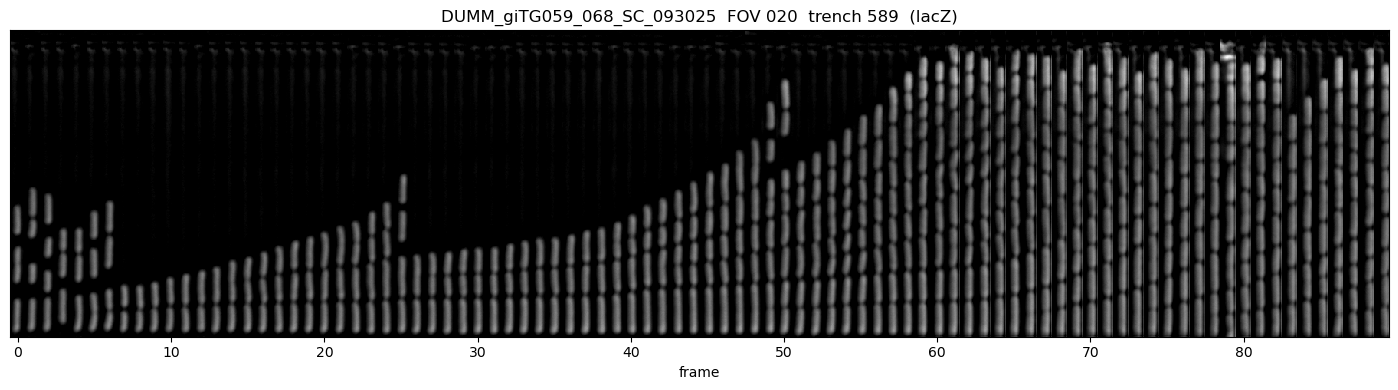

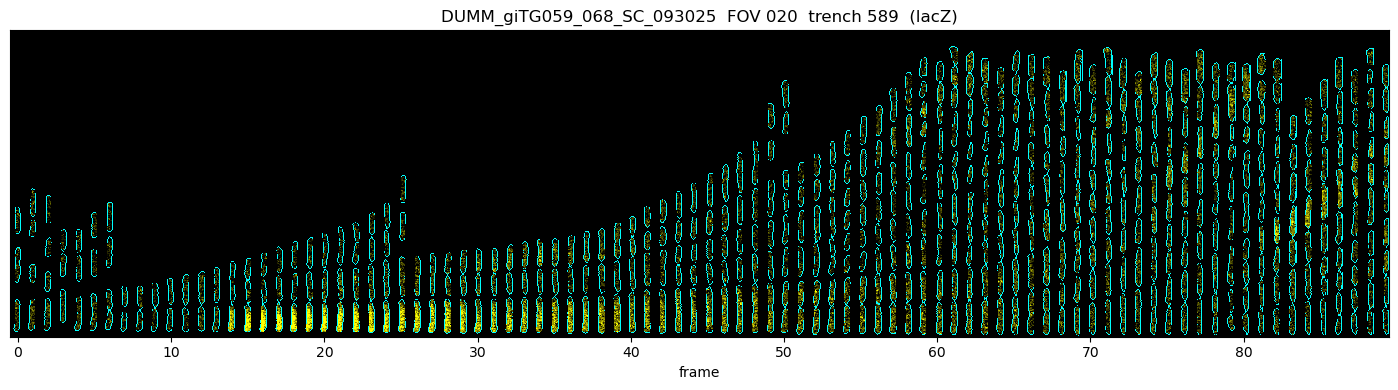

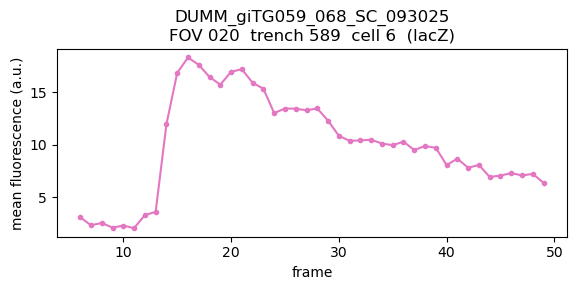

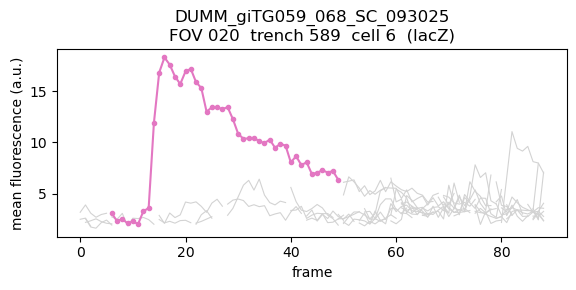

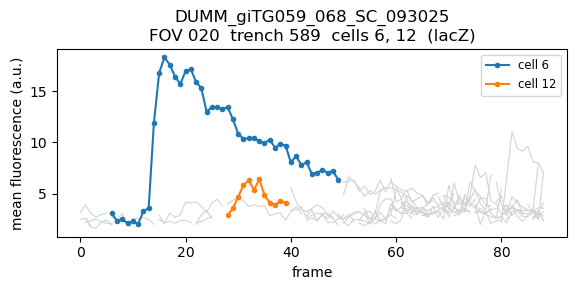

In [11]:
fig, ax = plot_phase_kymograph(exp_name, base_dir, FOV, trench_id)

fig, ax = plot_fluor_kymograph(exp_name, base_dir, FOV, trench_id)

fig, ax = plot_cell_fluor(exp_name, base_dir, FOV, trench_id, cell_id)

fig, ax = plot_trench_fluor(exp_name, base_dir, FOV, trench_id, cell_id)
fig, ax = plot_trench_fluor(exp_name, base_dir, FOV, trench_id, cell_ids)
plt.show()


## Batch figures for a table of trenches

Each row names a trench and the cells to highlight. Kymographs are made once per trench, a trench fluorescence plot per row (cells missing from the trench are left unhighlighted), and a single-cell plot per listed cell. Everything is saved to `figures/kymographs/` (PNG + SVG, 1200 dpi) rather than displayed.

In [12]:
# trenches and cells to make figures for; Cells is a comma-separated list of ctc track ids (blank = none)
FIGURE_TABLE = pd.DataFrame([
    ('alkA' , 'DUMM_giTG069_063_121125'     ,  1, 1192, '2'),
    ('alkA' , 'DUMM_giTG069_063_121125'     ,  1, 1192, '2, 4, 2003'),
    ('alkA' , 'DUMM_giTG069_063_121125'     ,  1,  654, '4,5'),
    ('araB' , 'CL008_giTG068_072925'        ,  3, 1598, '12,29,30'),
    ('araB' , 'CL008_giTG068_072925'        ,  3, 1598, '12, 25'),
    ('araB' , 'CL008_giTG068_072925'        ,  9,  551, '45,48'),
    ('araB' , 'CL008_giTG068_072925'        ,  7,   65, ''),
    ('baeS' , 'DUMM_giTG066_063_120925'     ,  2, 1979, '30,38,43,7,50,33'),
    ('baeS' , 'DUMM_gitg068_baeS_100225'    , 17,  726, '42,46, 37'),
    ('baeS' , 'DUMM_gitg068_baeS_100225'    , 18, 1260, ''),
    ('baeS' , 'DUMM_gitg068_baeS_100225'    , 19, 1063, ''),
    ('baeS' , 'DUMM_gitg068_baeS_100225'    , 21, 1930, '11'),
    ('gfcE' , 'DUMM_giTG060_064_121425'     , 13,  229, '7,3'),
    ('gfcE' , 'DUMM_giTG060_064_121425'     , 14,  226, '5, 19, 16, 25'),
    ('gfcE' , 'DUMM_giTG060_064_121425'     , 14,  226, '16,25'),
    ('gfcE' , 'DUMM_giTG064_Glucose_022625' ,  1,  239, '30,32,31'),
    ('gldA' , 'DUMM_giTG069_063_121125'     , 16, 1564, '9, 13'),
    ('gldA' , 'DUMM_giTG069_063_121125'     , 16, 1564, '9,24,23'),
    ('hupA' , 'DUMM_giTG068_063_061725'     , 12, 1165, ''),
    ('lacZ' , 'DUMM_giTG059_068_SC_093025'  , 15,  681, '49,59,60'),
    ('lacZ' , 'DUMM_giTG059_068_SC_093025'  , 15,  756, '66'),
    ('lacZ' , 'DUMM_giTG059_068_SC_093025'  , 20,  514, '11'),
    ('lacZ' , 'DUMM_giTG059_068_SC_093025'  , 20,  589, '6'),
    ('mazF' , 'DUMM_giTG059_060_061125'     , 15, 1826, ''),
], columns=['Gene', 'Experiment', 'FOV', 'Trench', 'Cells'])
FIGURE_TABLE['FOV'] = FIGURE_TABLE['FOV'].astype(str).str.zfill(3)
FIGURE_TABLE['Trench'] = FIGURE_TABLE['Trench'].astype(str)
FIGURE_TABLE['Cells'] = FIGURE_TABLE['Cells'].map(
    lambda s: [int(c) for c in s.replace(' ', '').split(',') if c])
FIGURE_TABLE

,Gene,Experiment,FOV,Trench,Cells
0,alkA,DUMM_giTG069_063_121125,001,1192,[2]
1,alkA,DUMM_giTG069_063_121125,001,1192,"[2, 4, 2003]"
2,alkA,DUMM_giTG069_063_121125,001,654,"[4, 5]"
3,araB,CL008_giTG068_072925,003,1598,"[12, 29, 30]"
4,araB,CL008_giTG068_072925,003,1598,"[12, 25]"
5,araB,CL008_giTG068_072925,009,551,"[45, 48]"
6,araB,CL008_giTG068_072925,007,65,[]
7,baeS,DUMM_giTG066_063_120925,002,1979,"[30, 38, 43, 7, 50, 33]"
8,baeS,DUMM_gitg068_baeS_100225,017,726,"[42, 46, 37]"
9,baeS,DUMM_gitg068_baeS_100225,018,1260,[]


In [13]:
# # kymographs once per trench; per row a trench plot with that row's cells highlighted,
# # then a single-cell plot for each cell (once per trench). Figures are saved, not shown.
# log = []
# def run(kind, row, fn, *args):
#     try:
#         fig, ax = fn(*args)
#         plt.close(fig)
#         log.append((row.Gene, row.Experiment, row.FOV, row.Trench, kind, 'saved'))
#     except Exception as err:
#         plt.close('all')
#         log.append((row.Gene, row.Experiment, row.FOV, row.Trench, kind, f'FAILED: {err}'))

# done_kymo, done_cell = set(), set()
# for row in FIGURE_TABLE.itertuples():
#     key = (row.Experiment, row.FOV, row.Trench)
#     meta_gene = gene_for(row.Experiment, row.FOV)
#     if meta_gene != row.Gene:
#         print(f'WARNING: {key} is listed as {row.Gene} but experiment_metadata says {meta_gene}')
#     if key not in done_kymo:
#         run('phase kymograph', row, plot_phase_kymograph, *[key[0], base_dir, key[1], key[2]])
#         run('fluor kymograph', row, plot_fluor_kymograph, *[key[0], base_dir, key[1], key[2]])
#         done_kymo.add(key)
#     run(f'trench plot {row.Cells}', row, plot_trench_fluor, row.Experiment, base_dir, row.FOV, row.Trench, row.Cells)
#     for c in row.Cells:
#         if (key, c) not in done_cell:
#             run(f'cell {c} plot', row, plot_cell_fluor, row.Experiment, base_dir, row.FOV, row.Trench, c)
#             done_cell.add((key, c))

# figure_log = pd.DataFrame(log, columns=['Gene', 'Experiment', 'FOV', 'Trench', 'figure', 'status'])
# print(f"{(figure_log.status == 'saved').sum()} figures saved to {FIG_DIR}, "
#       f"{(figure_log.status != 'saved').sum()} failed")
# figure_log[figure_log.status != 'saved']

## Average fluorescence per gene, across experiments

Left: raw `intensity_mean_fluor` (a.u.). Right: each experiment's values divided by that experiment's YFP exposure (`experiment_metadata.EXPOSURE_MS`, 150-500 ms), which is what makes experiments comparable. Each bar is the mean of the per-experiment means, so every experiment counts equally; dots are the individual experiments. Log y-axis.

  cells: dropped 1776 rows outside STRAIN_EXP_DICT
  cells: dropped 1097 rows in 2 excluded kymograph(s) (FAILED_KYMOGRAPHS)
dropped 4 kymographs from DUMM_giTG66_Glucose_012325


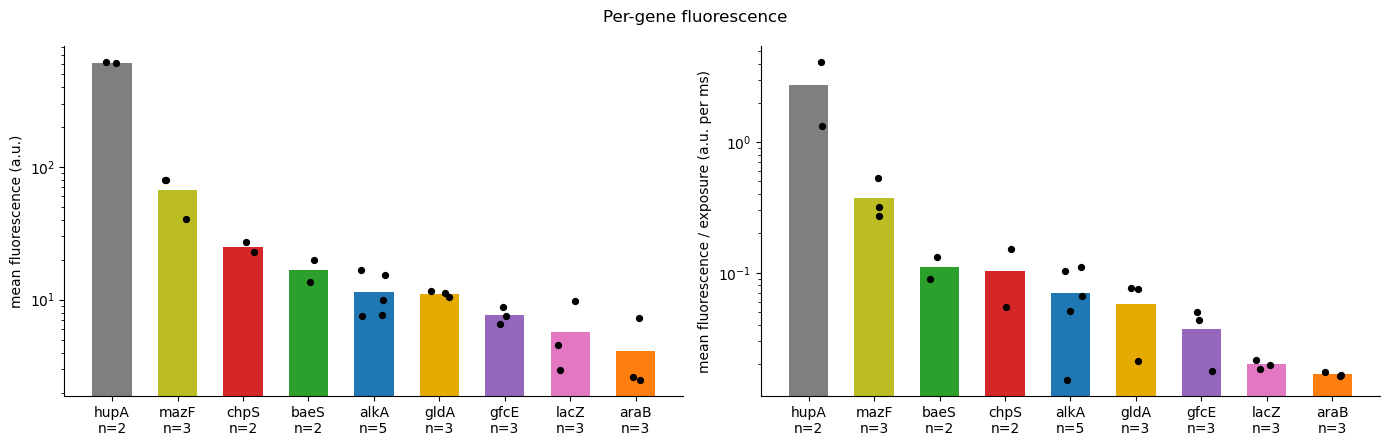

,n_experiments,raw,per_ms
gene,,,
alkA,5,11.465436,0.069415
araB,3,4.125461,0.016694
baeS,2,16.682808,0.111219
chpS,2,24.986206,0.102884
gfcE,3,7.653424,0.037246
gldA,3,11.100984,0.057706
lacZ,3,5.752864,0.019901
hupA,2,609.753117,2.726413
mazF,3,66.875638,0.374620


In [14]:
cells = bursts.load_cells(data_root=REPO, drop_excluded=False)
cells = bursts.drop_excluded_kymographs(cells, 'cells', require_match=False)
cells = cells[~cells['is_degenerate_mask']].reset_index(drop=True)

DROP_EXP = 'DUMM_giTG66_Glucose_012325'
n_drop = cells.loc[cells['experiment_name'] == DROP_EXP, ['FOV', 'trench_id']].drop_duplicates().shape[0]
assert n_drop == 4, f'expected 4 kymographs in {DROP_EXP}, found {n_drop}'
cells = cells[cells['experiment_name'] != DROP_EXP].reset_index(drop=True)
print(f'dropped {n_drop} kymographs from {DROP_EXP}')
cells['yfp_exposure_ms'] = cells['experiment_name'].map(lambda e: experiment_metadata.exposure_for(e)[1])
assert cells['yfp_exposure_ms'].notna().all(), 'experiment missing from EXPOSURE_MS'
cells['fluor_over_exposure'] = cells['intensity_mean_fluor'] / cells['yfp_exposure_ms']
assert np.allclose(cells['fluor_over_exposure'], cells['fluor_per_ms'], equal_nan=True)

# mean per experiment first, then average those, so every experiment counts equally
per_exp = (cells.groupby(['gene', 'experiment_name'])
                .agg(raw=('intensity_mean_fluor', 'mean'), per_ms=('fluor_over_exposure', 'mean'),
                     exposure_ms=('yfp_exposure_ms', 'first'))
                .reset_index())
genes = [g for g in GENE_COLOR if g in set(per_exp['gene'])]
summary = (per_exp.groupby('gene')
                  .agg(n_experiments=('experiment_name', 'size'), raw=('raw', 'mean'), per_ms=('per_ms', 'mean'))
                  .loc[genes])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rng = np.random.default_rng(0)
x = np.arange(len(genes))
for ax, col, ylabel, title in [
        (axes[0], 'raw', 'mean fluorescence (a.u.)', 'Raw'),
        (axes[1], 'per_ms', 'mean fluorescence / exposure (a.u. per ms)', 'Divided by YFP exposure')]:
    # each panel ranked by its own values, highest first; exposure changes the order
    ranked = summary.sort_values(col, ascending=False)
    ax.bar(x, ranked[col], color=[GENE_COLOR[g] for g in ranked.index], width=0.6)
    for xi, g in enumerate(ranked.index):
        vals = per_exp.loc[per_exp['gene'] == g, col]
        ax.scatter(xi + rng.uniform(-0.2, 0.2, len(vals)), vals, s=18, color='black', zorder=3)
    ax.set_xticks(x, [f'{g}\nn={n}' for g, n in zip(ranked.index, ranked['n_experiments'])])
    ax.set_yscale('log')   # hupA is ~10x every other gene
    ax.set_ylabel(ylabel)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'Per-gene fluorescence')
fig.tight_layout()
plt.show()
summary

## Bursts per gene and per cell cycle (v1 / v2 / v3 / manual)

Same figures as `trackastra_figures_100326.ipynb` §1b, recoloured with this notebook's `GENE_COLOR`. `manual` passes `unmeasured=UNREVIEWED`, so mazF/hupA read NOT MEASURED rather than a measured zero.

In [15]:
import mmtrack.figures as F
import mmtrack.bursts as b
F.GENE_COLOR.update(GENE_COLOR)        # use this notebook's palette in every F. plot
F.configure(save=False, label=F.scope_label(drop_failed=True), suffix='')

divisions = b.load_divisions(data_root=REPO)
union = pd.read_csv(f'{REPO}/data/bursts_viewer_v1v2v3manual_100226.csv', dtype=F.READ_DTYPES)
union['FOV'] = union['FOV'].str.zfill(3)

UNREVIEWED = bursts.UNREVIEWED_GENES   # ('hupA', 'mazF') -- never opened
DEFS = ('v1', 'v2', 'v3')

  divisions: dropped 108 rows outside STRAIN_EXP_DICT


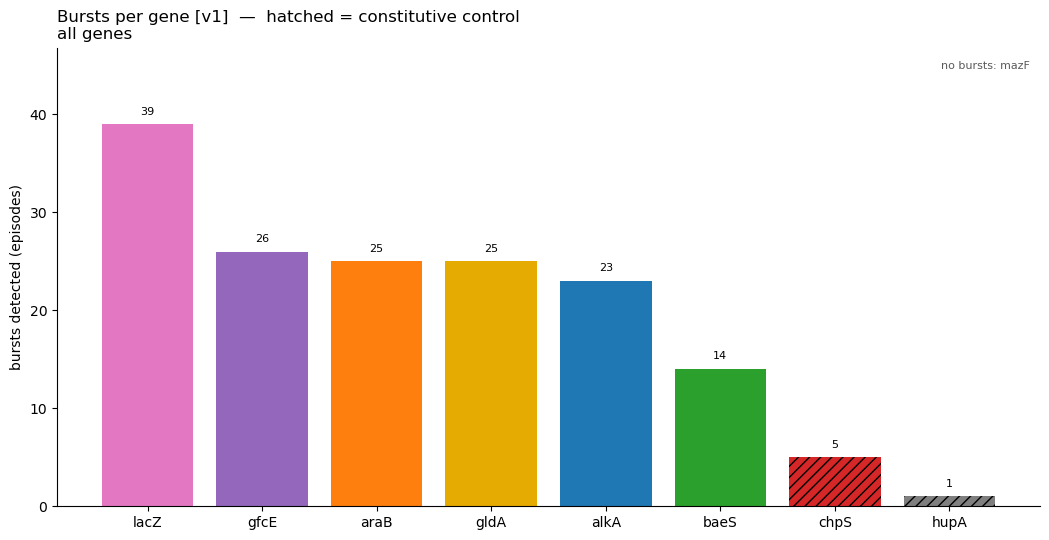

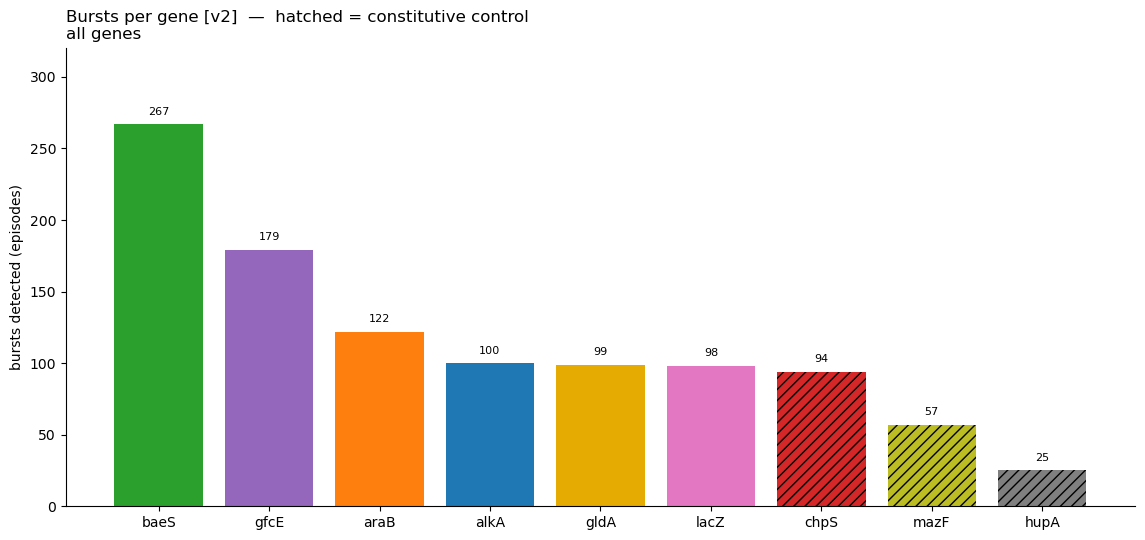

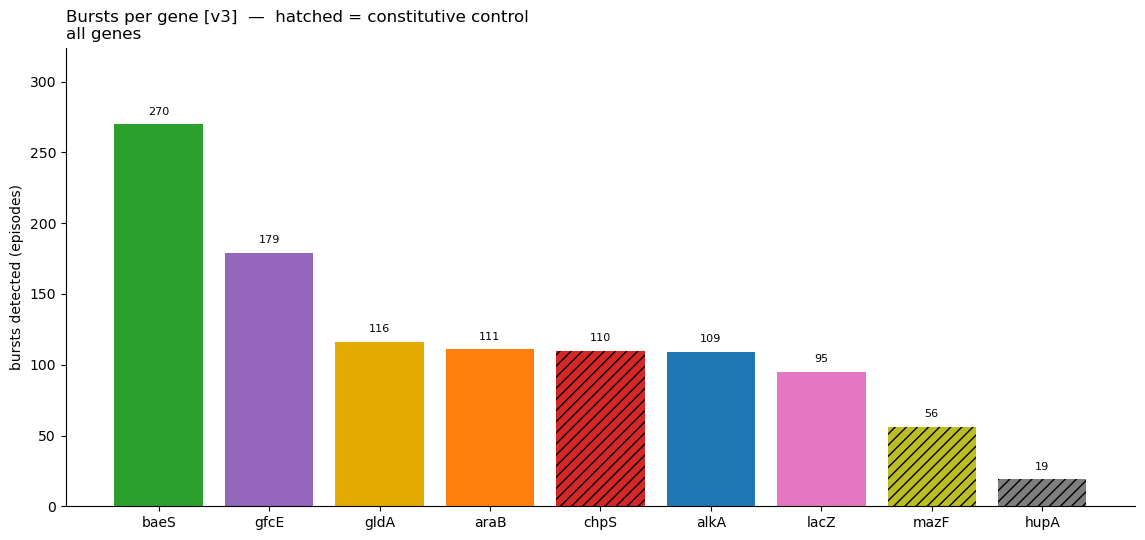

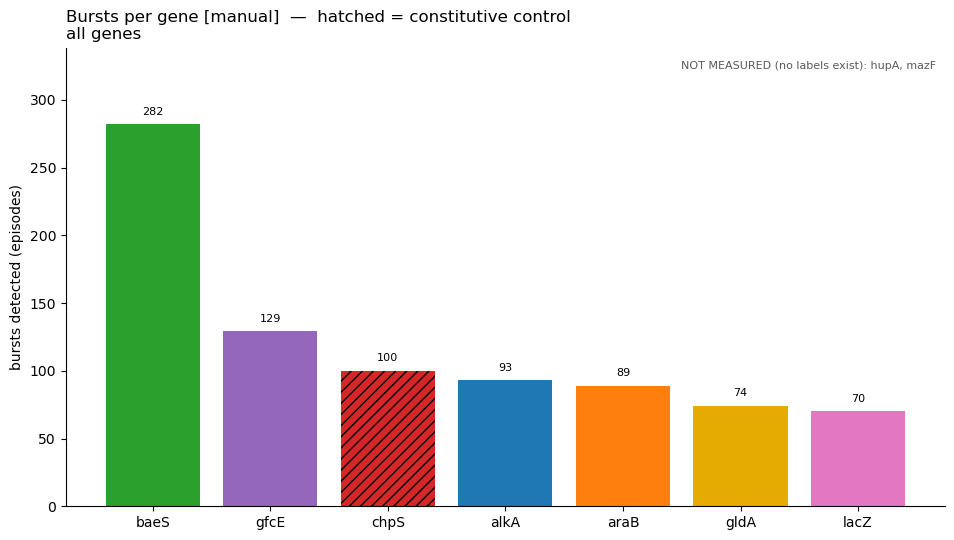

In [16]:
for _v in (*DEFS, 'manual'):
    _unm = UNREVIEWED if _v == 'manual' else ()
    F.plot_burst_counts(union, version=_v, by_experiment=False, unmeasured=_unm)
plt.show()

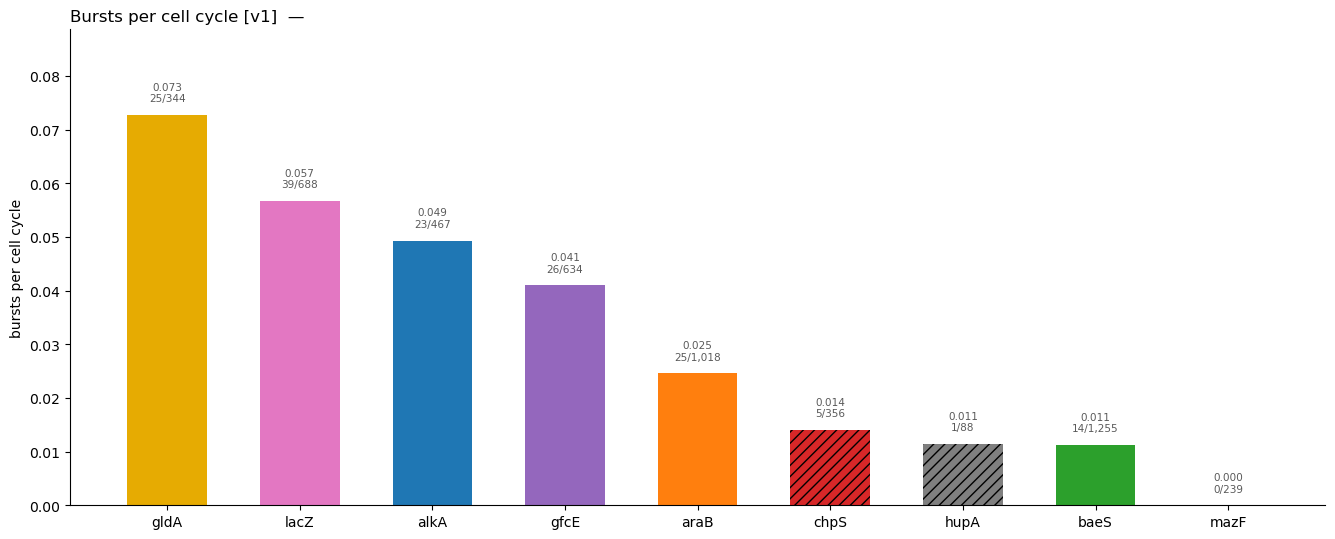

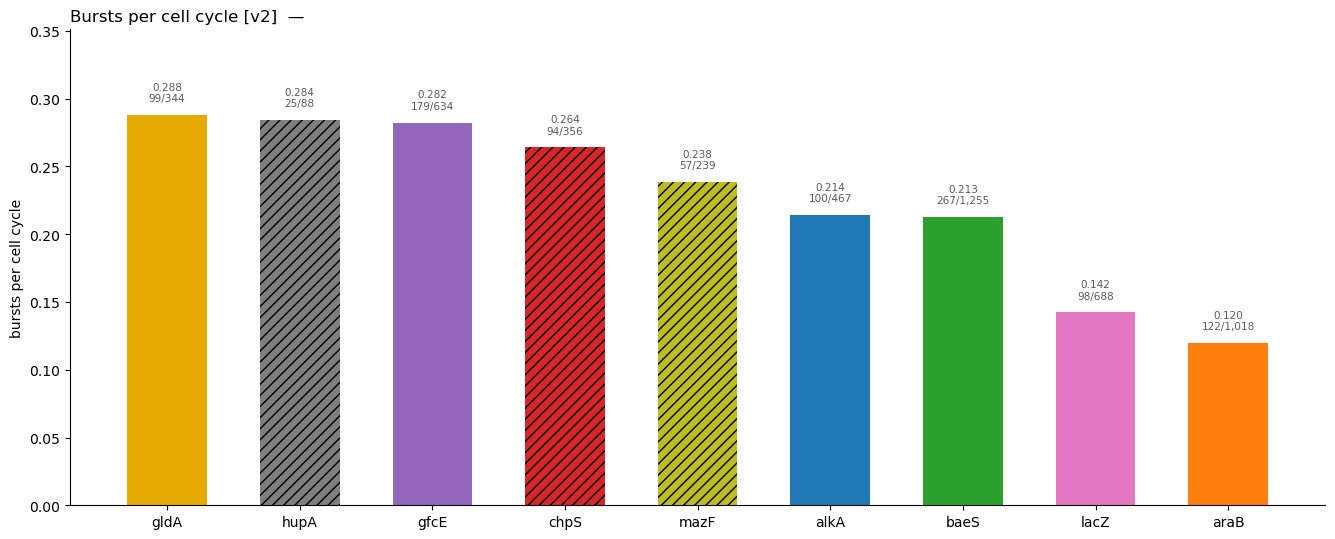

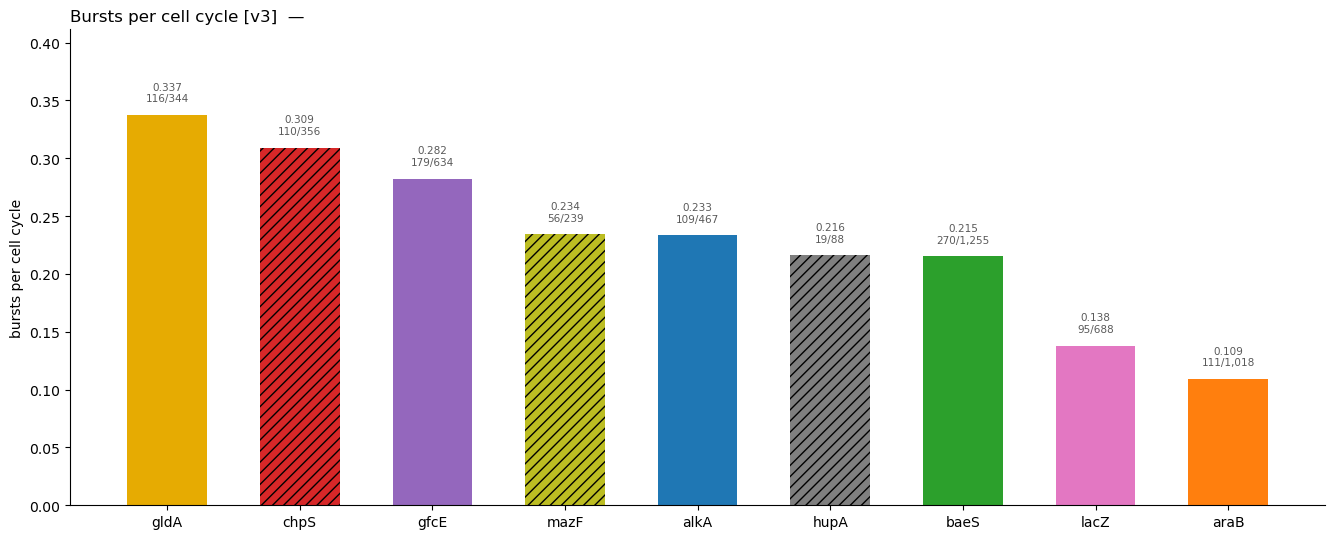

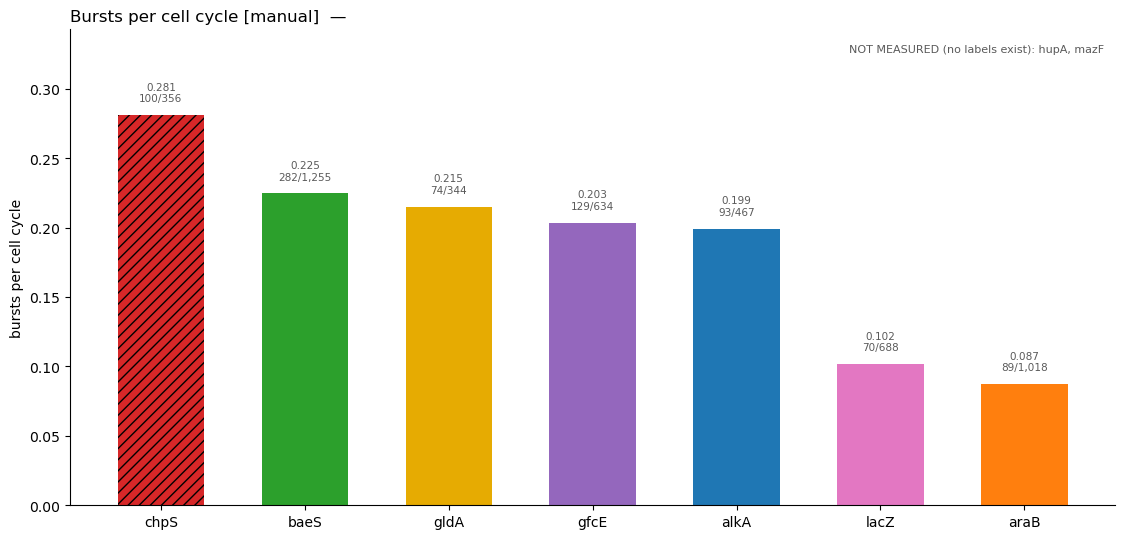

In [17]:
for _v in (*DEFS, 'manual'):
    _unm = UNREVIEWED if _v == 'manual' else ()
    F.plot_bursts_per_cell_cycle(union, divisions, version=_v, unmeasured=_unm)
plt.show()